In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Load the dataset
df = pd.read_csv('retail_sales_dataset.csv')

# 1. Display the first few rows
display(df.head())

# 2. Check the shape of the dataset
print(f"Dataset Shape: {df.shape}")

# 3. Check column data types and non-null counts
print("\n--- Data Types & Info ---")
df.info()

# 4. Check for null values
print("\n--- Null Value Check ---")
print(df.isnull().sum())

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


Dataset Shape: (1000, 9)

--- Data Types & Info ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 100.2 KB

--- Null Value Check ---
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [3]:
# Convert the Date column to datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Add a Markdown cell above this output in your notebook later to explain these stats!
print("--- Descriptive Statistics for Numerical Columns ---")
display(df.describe())

# To get the mode (most frequent value) specifically:
print("\n--- Mode of Numerical Columns ---")
display(df.mode().iloc[0])

--- Descriptive Statistics for Numerical Columns ---


,Transaction ID,Date,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,2023-07-03 00:25:55.200000,41.39200,2.514000,179.890000,456.000000
min,1.000000,2023-01-01 00:00:00,18.00000,1.000000,25.000000,25.000000
25%,250.750000,2023-04-08 00:00:00,29.00000,1.000000,30.000000,60.000000
50%,500.500000,2023-06-29 12:00:00,42.00000,3.000000,50.000000,135.000000
75%,750.250000,2023-10-04 00:00:00,53.00000,4.000000,300.000000,900.000000
max,1000.000000,2024-01-01 00:00:00,64.00000,4.000000,500.000000,2000.000000
std,288.819436,NaN,13.68143,1.132734,189.681356,559.997632



--- Mode of Numerical Columns ---


Transaction ID                        1
Date                2023-05-16 00:00:00
Customer ID                     CUST001
Gender                           Female
Age                                43.0
Product Category               Clothing
Quantity                            4.0
Price per Unit                     50.0
Total Amount                       50.0
Name: 0, dtype: object

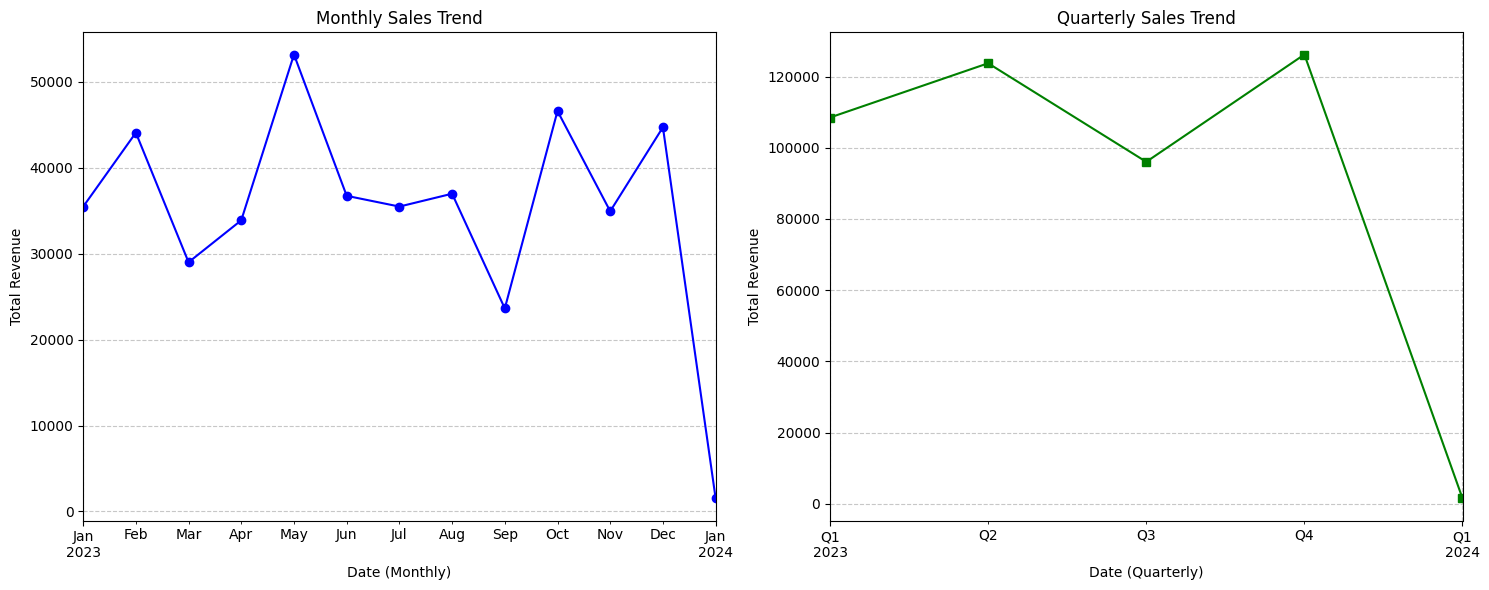

In [4]:
# Set 'Date' as the index for easier time-based grouping
df_time = df.set_index('Date')

# Calculate monthly and quarterly sales (summing the Total Amount)
# Note: 'ME' stands for Month-End and 'QE' for Quarter-End in newer pandas versions
monthly_sales = df_time['Total Amount'].resample('ME').sum()
quarterly_sales = df_time['Total Amount'].resample('QE').sum()

# Set up the matplotlib figure
plt.figure(figsize=(15, 6))

# 1. Monthly Sales Trend Chart
plt.subplot(1, 2, 1)
monthly_sales.plot(kind='line', marker='o', color='blue')
plt.title('Monthly Sales Trend')
plt.xlabel('Date (Monthly)')
plt.ylabel('Total Revenue')
plt.grid(True, linestyle='--', alpha=0.7)

# 2. Quarterly Sales Trend Chart
plt.subplot(1, 2, 2)
quarterly_sales.plot(kind='line', marker='s', color='green')
plt.title('Quarterly Sales Trend')
plt.xlabel('Date (Quarterly)')
plt.ylabel('Total Revenue')
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

**Observation: Sales Trends Over Time**
* **Monthly Trend:** Revenue fluctuates significantly throughout the year, with the highest peak occurring in May 2023, followed closely by strong sales in October 2023. The weakest full month for sales was September 2023. 
* **Quarterly Trend:** The quarterly aggregation reveals that Q4 2023 was the strongest performing quarter overall, closely followed by Q2. There is a noticeable dip in Q3. The sharp drop in January/Q1 2024 is likely due to the dataset containing incomplete data for that new year.

C:\Users\dp185\AppData\Local\Temp\ipykernel_27248\1695446720.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Gender', palette='pastel')


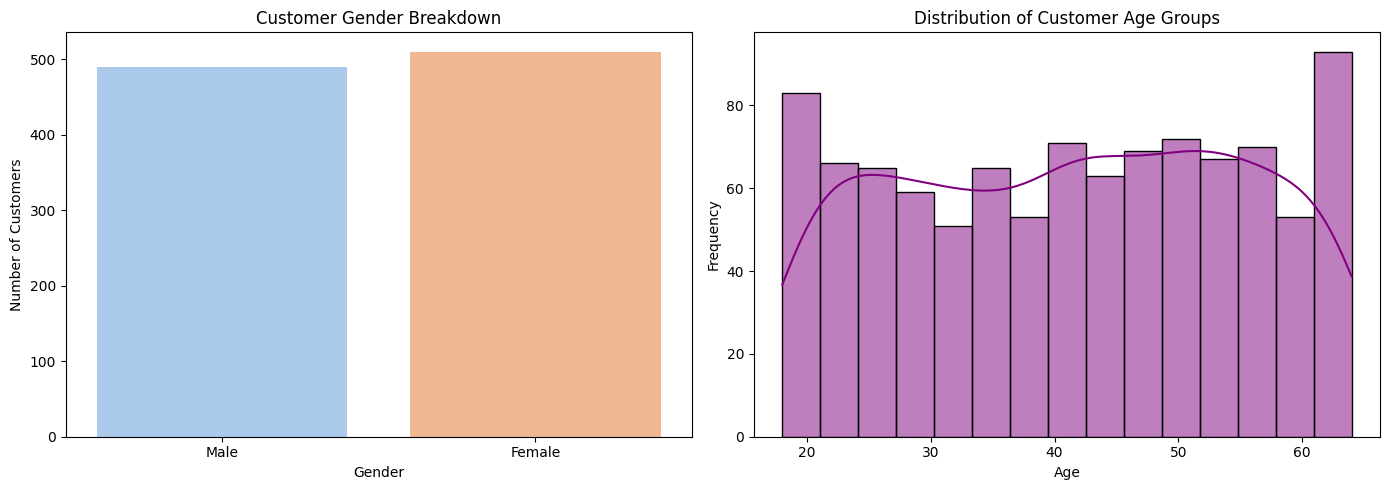

In [5]:
plt.figure(figsize=(14, 5))

# 1. Gender Breakdown (Countplot)
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='Gender', palette='pastel')
plt.title('Customer Gender Breakdown')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

# 2. Age Distribution (Histogram)
plt.subplot(1, 2, 2)
sns.histplot(data=df, x='Age', bins=15, kde=True, color='purple')
plt.title('Distribution of Customer Age Groups')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

**Observation: Customer Demographics**
* **Gender Breakdown:** The customer base is almost evenly split between genders, with female customers making up a slightly larger portion of the total count compared to male customers.
* **Age Distribution:** Customers span a wide age range from roughly 18 to 64 years old. The distribution is relatively balanced across most age groups, but there are distinct peaks at the youngest demographic (around 18-20 years old) and the oldest demographic (60+ years old), indicating strong engagement at both ends of the age spectrum.

C:\Users\dp185\AppData\Local\Temp\ipykernel_27248\2026737810.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=revenue_by_category.index, y=revenue_by_category.values, palette='viridis')
C:\Users\dp185\AppData\Local\Temp\ipykernel_27248\2026737810.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=quantity_by_category.index, y=quantity_by_category.values, palette='magma')


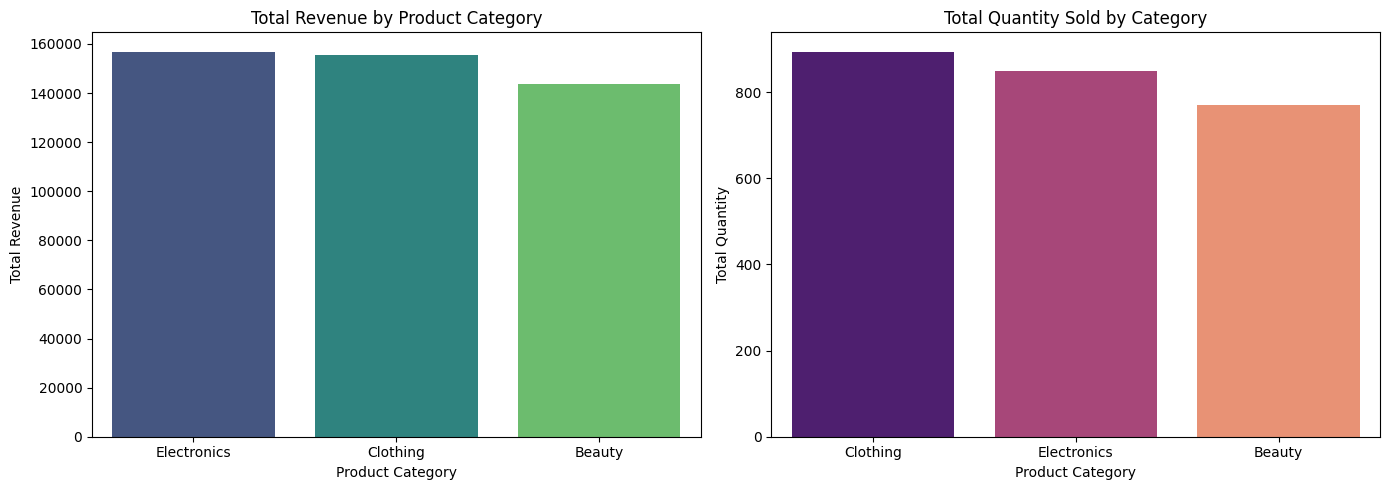

In [6]:
plt.figure(figsize=(14, 5))

# 1. Revenue by Product Category (Bar Chart)
plt.subplot(1, 2, 1)
revenue_by_category = df.groupby('Product Category')['Total Amount'].sum().sort_values(ascending=False)
sns.barplot(x=revenue_by_category.index, y=revenue_by_category.values, palette='viridis')
plt.title('Total Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')

# 2. Quantity Sold by Product Category
plt.subplot(1, 2, 2)
quantity_by_category = df.groupby('Product Category')['Quantity'].sum().sort_values(ascending=False)
sns.barplot(x=quantity_by_category.index, y=quantity_by_category.values, palette='magma')
plt.title('Total Quantity Sold by Category')
plt.xlabel('Product Category')
plt.ylabel('Total Quantity')

plt.tight_layout()
plt.show()

**Observation: Product Category Performance**
* **Revenue vs. Volume:** Electronics generates the highest total revenue, closely followed by Clothing. However, Clothing leads in total quantity sold. This indicates that while Clothing moves more volume, Electronics has a higher average unit price that drives greater overall revenue.
* **Category Laggard:** The Beauty category ranks third in both total revenue and quantity sold, though it still maintains a robust sales volume, showing that all three primary categories are strong contributors to the business.

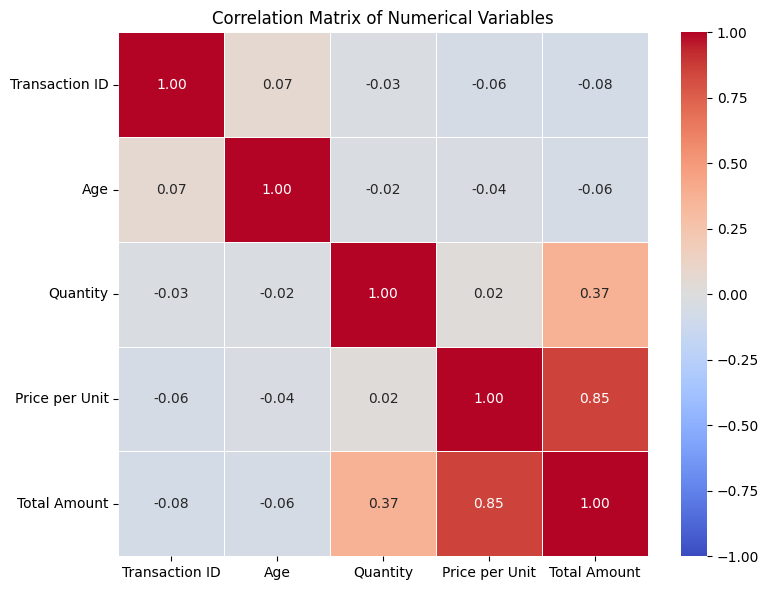

In [7]:
plt.figure(figsize=(8, 6))

# Filter for only numerical columns to calculate correlation
numerical_cols = df.select_dtypes(include=['int64', 'float64'])

# Generate the correlation heatmap
sns.heatmap(numerical_cols.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5, fmt=".2f")
plt.title('Correlation Matrix of Numerical Variables')

plt.tight_layout()
plt.show()

**Observation: Correlation Matrix**
* **Primary Revenue Driver:** There is a very strong positive correlation (0.85) between `Price per Unit` and `Total Amount`, while `Quantity` has a much weaker correlation (0.37) with the total. This suggests that revenue is driven more by selling higher-ticket items rather than simply selling higher volumes of cheap items.
* **Age Independence:** `Age` shows virtually zero correlation with `Total Amount` (-0.06) or `Quantity` (-0.02). This means customer spending habits in this dataset are not dictated by their age.

### Conclusion & Business Recommendations

Based on the exploratory data analysis, here are three actionable recommendations to drive business growth:

1. **Optimize Promotional Timing for Q3:** Sales dip significantly in September and throughout Q3. The business should introduce targeted promotions, bundle deals, or clearance sales during this period to stimulate demand, while saving primary marketing budgets for the proven peak seasons in May and Q4.

2. **Cross-Sell to Leverage Clothing Volume:** While Electronics generates the most revenue, Clothing drives the highest sales volume. The business should implement cross-selling strategies—such as placing high-margin electronic accessories near clothing checkouts or offering "wearable tech" bundles—to convert high-volume clothing shoppers into higher-ticket electronics buyers.

3. **Broaden Marketing Demographics:** Since customer spending (Total Amount) and purchasing volume (Quantity) have virtually zero correlation with Age, and the gender split is highly balanced, marketing campaigns should avoid narrow age-gating. Instead, advertising should focus on lifestyle, product utility, and broad appeal across all adult demographics.